# Nomor 2 · Visualisasi kesehatan dan degradasi baterai EV

**Tujuan:** menghasilkan informasi dari visualisasi, lalu menafsirkan artinya untuk
prioritas pemeriksaan pada **skenario armada simulasi**.

Data disediakan pengguna dari [Kaggle, Vinay Baghira](https://www.kaggle.com/datasets/vinay24baghira/ev-battery-health-and-degradation-dataset).
Menurut README di arsip, dataset ini **sepenuhnya sintetis**, dengan pengukuran berulang
pada baterai yang sama. Angkanya tidak mewakili prevalensi kegagalan kendaraan nyata.

Notebook mencakup audit kualitas, pemilihan unit analisis, enam visual utama,
penjelasan alasan pemilihan grafik, informasi, informasi strategis, dan batas interpretasi.
Jalankan **Restart Kernel and Run All**. Tidak ada unduhan data saat eksekusi.

## 1. Konsep dan pertanyaan

**Informasi:** hasil yang menjelaskan kondisi, misalnya proporsi rekaman baterai terakhir
dengan SOH di bawah 80%. **Informasi strategis:** arti hasil itu bagi tujuan tertentu,
misalnya kebutuhan memeriksa kapasitas layanan inspeksi pada skenario armada.
Usulan tindakan adalah langkah berikutnya yang perlu diuji, bukan fakta baru dari grafik.

SOH (*State of Health*) menyatakan kapasitas saat ini sebagai persentase kapasitas nominal.
SOH 80% dalam dokumentasi merupakan ambang akhir masa guna untuk target estimasi dataset,
bukan aturan universal penggantian atau ukuran keamanan baterai.

Pertanyaan:
1. Bagaimana sebaran SOH pada rekaman terakhir setiap baterai?
2. Bagaimana hubungan siklus pemakaian dengan SOH pada data simulasi?
3. Bagaimana perbandingan antarjenis kimia jika umur pemakaian turut diperhatikan?
4. Berapa kandidat pemeriksaan berdasarkan aturan ilustratif, dan seberapa sensitif terhadap ambang?

In [1]:
from pathlib import Path
import hashlib
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

def temukan_root():
    # Mendukung peluncuran dari folder Analisis, RISET30OKTOBER, atau workspace.
    for calon in [Path.cwd(), *Path.cwd().parents]:
        for lokasi in [calon, calon / 'RISET30OKTOBER']:
            if (lokasi / 'Battery/Dataset/ev_battery_health.csv').exists() and (lokasi / 'Apple/Dataset/financial_facts.csv').exists():
                return lokasi
    raise FileNotFoundError('Letakkan folder Analisis di dalam RISET30OKTOBER, bersama Battery dan Apple.')

ROOT = temukan_root()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'savefig.dpi': 160})
WARNA = {'utama':'#156B86', 'hijau':'#087D59', 'ungu':'#7045D9', 'jingga':'#B75B30', 'abu':'#64706F'}

def angka(v, desimal=2):
    return f'{v:,.{desimal}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def simpan_grafik(fig, nama):
    fig.savefig(HASIL / nama, bbox_inches='tight')
    plt.show()

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [2]:
SUMBER = ROOT / 'Battery/Dataset'
HASIL = ROOT / 'Analisis/hasil/battery'
HASIL.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(SUMBER / 'ev_battery_health.csv')
dictionary = pd.read_csv(SUMBER / 'data_dictionary .csv')
with zipfile.ZipFile(SUMBER / 'archive.zip') as z:
    readme_sumber = z.read('README.md').decode('utf-8')
assert 'fully synthetic' in readme_sumber.lower()
print('Ukuran data:', raw.shape, '| Baterai unik:', raw['battery_id'].nunique())
display(raw[['battery_id','observation_id','observation_date','chemistry','cycle_count',
             'state_of_health_pct','failure_risk_label']].head())
display(dictionary[dictionary['column'].isin(['state_of_health_pct','capacity_fade_pct',
                                           'remaining_useful_life_cycles','failure_risk_label'])])

Ukuran data: (50000, 35) | Baterai unik: 2600


,battery_id,observation_id,observation_date,chemistry,cycle_count,state_of_health_pct,failure_risk_label
0,BATT_01748,OBS_033554,2024-10-16,LMO,991.00,80.87,High
1,BATT_00491,OBS_009428,2024-12-27,LFP,"1,535.00",91.81,Low
2,BATT_00011,OBS_000200,2026-02-10,LFP,407.00,97.48,Low
3,BATT_00651,OBS_012448,2022-09-15,NMC,29.00,99.18,Low
4,BATT_02054,OBS_039490,2026-03-01,NCA,324.00,91.86,Low


,column,dtype,unit,description,example_value
26,capacity_fade_pct,float,%,Cumulative capacity fade from nominal (100 - SOH),8.19
31,state_of_health_pct,float [TARGET],%,State of Health: current capacity as % of nomi...,91.81
32,remaining_useful_life_cycles,int [TARGET],cycles,Estimated remaining cycles until SOH reaches 8...,1739
33,failure_risk_label,categorical [TARGET],-,Classification target: Low / Medium / High nea...,Low


## 2. Audit kualitas dan perlakuan data

Satu baris adalah **satu pengamatan**, bukan satu baterai. Baterai dengan lebih banyak
rekaman akan berbobot lebih besar jika semua baris langsung dipakai menghitung prevalensi.

Nilai kosong dilaporkan per kolom. Nilai kosong pada `last_service_date` dapat berarti belum
pernah servis atau informasi hilang, sehingga tidak langsung dianggap kesalahan.
Sensor ekstrem dipertahankan dan dilaporkan, karena dokumentasi menyebut injeksi pencilan.
Tidak ada penghapusan otomatis memakai IQR atau pengisian rata-rata global.

,kolom,kosong,kosong_pct
28,last_service_date,18831,37.66
4,vehicle_model,3515,7.03
2,chemistry,3459,6.92
13,fast_charge_ratio,3405,6.81
17,total_energy_throughput_kwh,3370,6.74
18,avg_ambient_temp_c,3282,6.56
15,avg_state_of_charge_pct,3138,6.28
8,battery_age_days,3002,6.00
14,avg_depth_of_discharge_pct,2832,5.66
22,voltage_avg_v,2807,5.61


Duplikasi baris penuh: 0
Duplikasi ID observasi: 0
Rentang tanggal observasi: 2020-10-07 s.d. 2026-09-27
Baris tanpa tanggal observasi: 2216
Suhu lingkungan > 60°C (diagnostik, tetap disimpan): 37
Baris yang berbagi baterai dan tanggal valid: 0


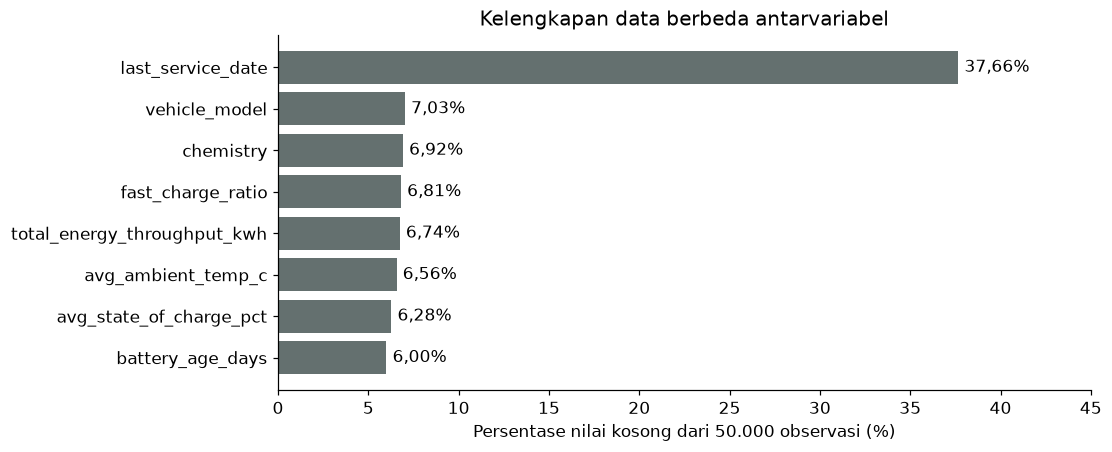

In [3]:
audit = pd.DataFrame({'kolom': raw.columns, 'kosong': raw.isna().sum().values})
audit['kosong_pct'] = audit['kosong'] / len(raw) * 100
audit = audit.sort_values('kosong_pct', ascending=False)
display(audit)
print('Duplikasi baris penuh:', raw.duplicated().sum())
print('Duplikasi ID observasi:', raw['observation_id'].duplicated().sum())
assert raw['observation_id'].is_unique
assert raw[['battery_id','observation_id','state_of_health_pct','failure_risk_label']].notna().all().all()
assert raw['state_of_health_pct'].between(0, 100).all()
assert raw['fast_charge_ratio'].dropna().between(0, 1).all()
assert set(raw['failure_risk_label']) <= {'Low','Medium','High'}

data = raw.copy()
for kolom in ['observation_date','manufacture_date','last_service_date']:
    data[kolom] = pd.to_datetime(data[kolom], errors='coerce')
    assert data[kolom].isna().sum() == raw[kolom].isna().sum(), f'Tanggal gagal dibaca: {kolom}'
valid = data.dropna(subset=['observation_date']).copy()
print('Rentang tanggal observasi:', valid['observation_date'].min().date(), 's.d.', valid['observation_date'].max().date())
print('Baris tanpa tanggal observasi:', len(data) - len(valid))
print('Suhu lingkungan > 60°C (diagnostik, tetap disimpan):', data['avg_ambient_temp_c'].gt(60).sum())
print('Baris yang berbagi baterai dan tanggal valid:', valid.duplicated(['battery_id','observation_date'], keep=False).sum())
assert not (valid['observation_date'] < valid['manufacture_date']).any()
age_check = (valid['observation_date'] - valid['manufacture_date']).dt.days
assert (age_check - valid['battery_age_days']).dropna().abs().le(1).all()
audit.to_csv(HASIL / 'audit_missing.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
top = audit.head(8).sort_values('kosong_pct')
bars = ax.barh(top['kolom'], top['kosong_pct'], color=WARNA['abu'])
ax.bar_label(bars, labels=[f'{angka(v)}%' for v in top['kosong_pct']], padding=4)
ax.set(xlim=(0, 45), xlabel='Persentase nilai kosong dari 50.000 observasi (%)',
       title='Kelengkapan data berbeda antarvariabel')
simpan_grafik(fig, '00_kualitas_data.png')

**Mengapa batang horizontal?** Nama kolom panjang tetap terbaca dan besarnya kehilangan data mudah
dibandingkan dari panjang batang. Semua penyebut adalah jumlah baris yang sama.
Informasi kualitas ini menentukan variabel dan pasangan data yang layak dianalisis.

## 3. Unit analisis satu baterai satu rekaman terakhir

Pilih tanggal observasi valid paling akhir per `battery_id`. Setiap baterai mendapat satu suara.
Jika ada lebih dari satu rekaman pada tanggal terakhir, notebook berhenti untuk meminta kebijakan agregasi,
bukan memilih seolah-olah tanggal memuat waktu yang lebih presisi.

Snapshot ini adalah **rekaman terakhir yang tersedia per baterai**, dengan tanggal yang berbeda-beda.
Ini bukan sensus pada satu tanggal bersama. Pengamatan tanpa tanggal tidak dipakai menentukan urutan,
sehingga rekaman terpilih belum tentu pengukuran terakhir yang sebenarnya.

Jenis kimia yang hilang pada snapshot hanya dipulihkan dari rekaman baterai yang sama
setelah memeriksa bahwa seluruh nilai kimia nonkosong per ID konsisten. Variabel sensor tidak diimputasi.

In [4]:
terakhir = valid[valid['observation_date'].eq(valid.groupby('battery_id')['observation_date'].transform('max'))]
assert terakhir['battery_id'].is_unique, 'Ada tanggal terakhir ganda; tentukan agregasi sebelum melanjutkan.'
snapshot = terakhir.sort_values('battery_id').reset_index(drop=True).copy()
assert len(snapshot) == raw['battery_id'].nunique()
assert data.groupby('battery_id')['chemistry'].nunique().le(1).all()
kimia_id = data.dropna(subset=['chemistry']).drop_duplicates('battery_id').set_index('battery_id')['chemistry']
kimia_diisi = int(snapshot['chemistry'].isna().sum())
snapshot['chemistry'] = snapshot['chemistry'].fillna(snapshot['battery_id'].map(kimia_id))
assert snapshot['chemistry'].notna().all()
print('Baterai dalam snapshot:', len(snapshot))
print('Jenis kimia dipulihkan dari ID yang sama:', kimia_diisi)
print('Rentang tanggal snapshot:', snapshot['observation_date'].min().date(), 's.d.', snapshot['observation_date'].max().date())
display(snapshot[['battery_id','observation_date','chemistry','state_of_health_pct','failure_risk_label']].head())

Baterai dalam snapshot: 2600
Jenis kimia dipulihkan dari ID yang sama: 199
Rentang tanggal snapshot: 2024-09-04 s.d. 2026-09-27


,battery_id,observation_date,chemistry,state_of_health_pct,failure_risk_label
0,BATT_00001,2026-09-01,NMC,80.51,Medium
1,BATT_00002,2026-09-24,LFP,99.54,Low
2,BATT_00003,2026-01-15,NCA,67.56,High
3,BATT_00004,2025-12-12,LFP,92.95,Low
4,BATT_00005,2026-08-03,NMC,85.91,Low


## 4. Visual 1 Sebaran SOH pada snapshot

Histogram memperlihatkan distribusi kontinu, tidak hanya rata-rata. Lebar bin 5 poin
menjaga keterbacaan. Sumbu SOH 0–100% memperlihatkan domain persentase, dan garis vertikal
menandai ambang ilustratif 80%. Sumbu frekuensi dimulai dari nol.

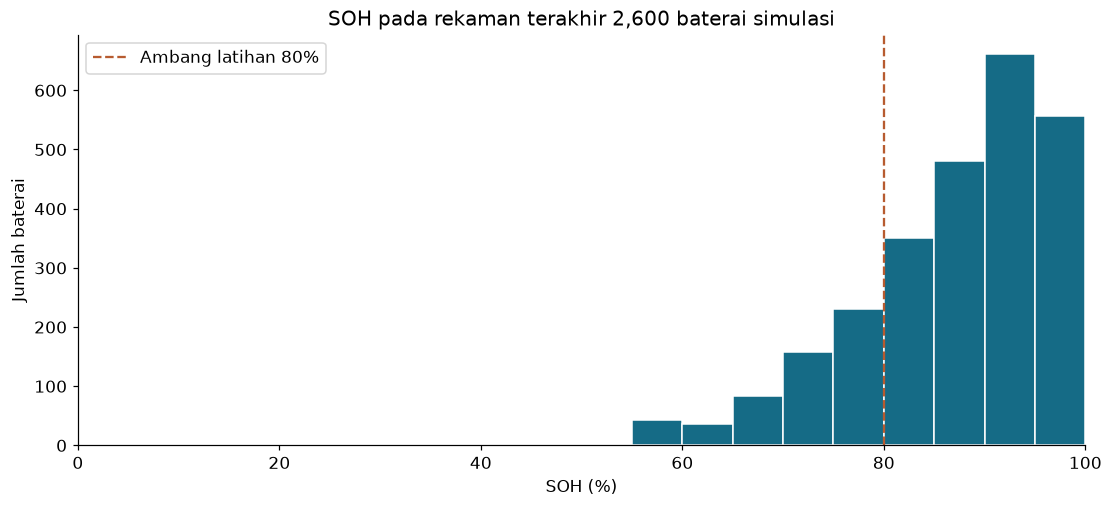

**Informasi:** median SOH **89,26%**. Sebanyak **550 dari 2,600 baterai (21,15%)** memiliki SOH < 80% pada rekaman terpilih.

In [5]:
soh = snapshot['state_of_health_pct']
n_rendah = int(soh.lt(80).sum())
median_soh = float(soh.median())
hist_count, hist_edges = np.histogram(soh, bins=np.arange(0, 105, 5))
pd.DataFrame({'batas_bawah':hist_edges[:-1], 'batas_atas':hist_edges[1:], 'jumlah':hist_count}).to_csv(HASIL / 'histogram_soh.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.hist(soh, bins=np.arange(0, 105, 5), color=WARNA['utama'], edgecolor='white')
ax.axvline(80, color=WARNA['jingga'], linestyle='--', label='Ambang latihan 80%')
ax.set(xlim=(0, 100), xlabel='SOH (%)', ylabel='Jumlah baterai',
       title=f'SOH pada rekaman terakhir {len(snapshot):,} baterai simulasi')
ax.legend()
simpan_grafik(fig, '01_distribusi_soh.png')
display(Markdown(f'**Informasi:** median SOH **{angka(median_soh)}%**. '
                 f'Sebanyak **{n_rendah:,} dari {len(snapshot):,} baterai ({angka(n_rendah/len(snapshot)*100)}%)** '
                 'memiliki SOH < 80% pada rekaman terpilih.'))

**Informasi strategis:** untuk skenario perencanaan armada simulasi, ekor distribusi SOH rendah
memberi gambaran kebutuhan pemeriksaan kapasitas. **Usulan:** kaji beban inspeksi berdasarkan kondisi,
bukan hanya umur kalender. Nilai SOH rendah sendiri belum membuktikan baterai berbahaya.

## 5. Visual 2 Hubungan siklus dan SOH

Hexbin mengelompokkan pasangan titik yang berdekatan sehingga 2.600 baterai tidak menumpuk.
Warna menunjukkan kepadatan **jumlah baterai**, bukan probabilitas kegagalan.
Hanya pasangan lengkap dengan siklus nonnegatif yang digunakan; seluruh penghapusan bersifat lokal per visual.

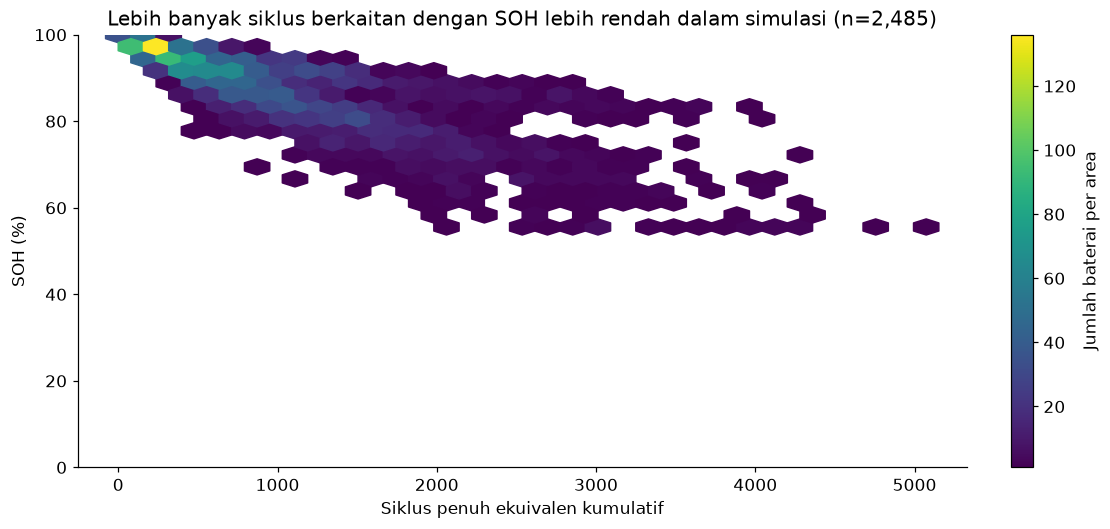

**Informasi:** korelasi Pearson siklus–SOH **r = -0,819**, dari **2,485 pasangan lengkap**. Korelasi ini mengukur hubungan dalam data sintetis, bukan besar pengaruh kausal.

In [6]:
pasangan = snapshot.dropna(subset=['cycle_count','state_of_health_pct']).copy()
pasangan = pasangan[pasangan['cycle_count'].ge(0)]
r_siklus = float(pasangan[['cycle_count','state_of_health_pct']].corr().iloc[0,1])
fig, ax = plt.subplots(figsize=(10, 4.7), layout='constrained')
hb = ax.hexbin(pasangan['cycle_count'], pasangan['state_of_health_pct'], gridsize=32,
               mincnt=1, cmap='viridis', extent=(0, float(pasangan['cycle_count'].max()), 0, 100))
fig.colorbar(hb, ax=ax, label='Jumlah baterai per area')
ax.set(xlabel='Siklus penuh ekuivalen kumulatif', ylabel='SOH (%)', ylim=(0,100),
       title=f'Lebih banyak siklus berkaitan dengan SOH lebih rendah dalam simulasi (n={len(pasangan):,})')
simpan_grafik(fig, '02_siklus_soh.png')
display(Markdown(f'**Informasi:** korelasi Pearson siklus–SOH **r = {angka(r_siklus,3)}**, '
                 f'dari **{len(pasangan):,} pasangan lengkap**. '
                 'Korelasi ini mengukur hubungan dalam data sintetis, bukan besar pengaruh kausal.'))

**Informasi strategis:** siklus kumulatif layak menjadi salah satu variabel pemantauan dalam prototipe,
bersama umur dan kondisi penggunaan. **Usulan:** evaluasi aturan pemeriksaan pada kelompok siklus tinggi.
Model generator sudah memasukkan degradasi karena siklus, sehingga hubungan ini tidak menjadi bukti baru
bahwa pola yang sama memiliki ukuran pengaruh identik pada kendaraan nyata.

## 6. Visual 3 Perbandingan jenis kimia

Boxplot memperlihatkan median dan sebaran SOH untuk setiap jenis kimia.
Whisker mengikuti aturan 1,5 IQR dan titik di luar whisker tetap ditampilkan.
Urutan kategori tetap LFP, NMC, NCA, LMO, bukan urutan yang berubah untuk memperkuat cerita.

,n,median_soh,median_umur_hari
chemistry,,,
LFP,784,93.03,"1,039.00"
NMC,890,87.79,"1,017.00"
NCA,545,84.77,"1,106.00"
LMO,381,82.40,"1,018.00"


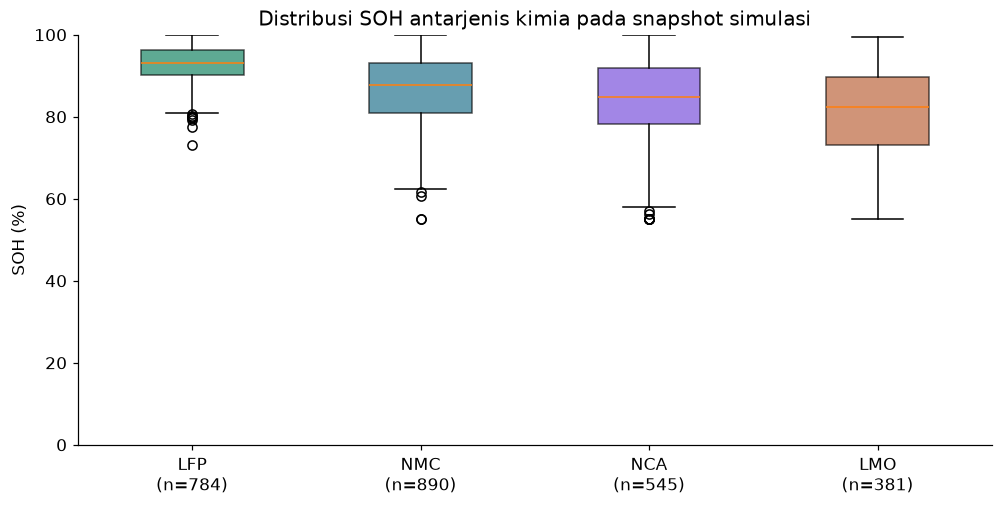

**Informasi:** median SOH menurut kimia: LFP **93,03%**; NMC **87,79%**; NCA **84,77%**; LMO **82,40%**.

In [7]:
URUTAN = ['LFP','NMC','NCA','LMO']
kimia = snapshot.groupby('chemistry').agg(n=('battery_id','size'), median_soh=('state_of_health_pct','median'),
                                        median_umur_hari=('battery_age_days','median')).reindex(URUTAN)
display(kimia)
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
bp = ax.boxplot([snapshot.loc[snapshot['chemistry'].eq(k),'state_of_health_pct'] for k in URUTAN],
                 tick_labels=[f'{k}\n(n={int(kimia.loc[k,"n"])})' for k in URUTAN], patch_artist=True)
for box, warna in zip(bp['boxes'], ['#087D59','#156B86','#7045D9','#B75B30']): box.set_facecolor(warna); box.set_alpha(.65)
ax.set(ylim=(0,100), ylabel='SOH (%)', title='Distribusi SOH antarjenis kimia pada snapshot simulasi')
simpan_grafik(fig, '03_kimia_boxplot.png')
display(Markdown('**Informasi:** median SOH menurut kimia: ' + '; '.join(f'{k} **{angka(kimia.loc[k,"median_soh"])}%**' for k in URUTAN) + '.'))

**Informasi strategis:** perbedaan sebaran membantu merancang evaluasi yang dibedakan per kimia,
bukan menetapkan satu angka rata-rata untuk semua baterai. Perbandingan ini belum mengisolasi
umur, siklus, iklim, dan kebiasaan pengisian. Tidak digunakan untuk menyatakan satu kimia paling unggul di dunia nyata.

## 7. Visual 4 Perbandingan dalam kelompok umur

Heatmap membandingkan median SOH kimia pada kelompok umur yang sama. Sel memuat jumlah baterai
agar kelompok kecil terlihat. Umur yang kosong dikeluarkan hanya dari visual ini.
Kelompok umur mengurangi satu sumber perbedaan komposisi, namun tidak mengontrol semua perancu.

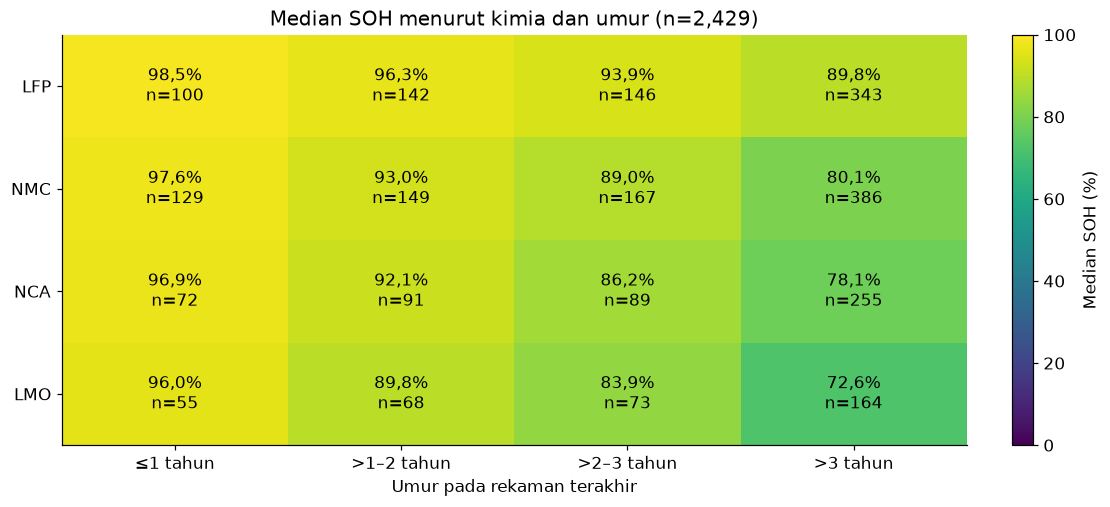

,chemistry,kelompok_umur,median_soh,n
0,LFP,≤1 tahun,98.47,100
1,LFP,>1–2 tahun,96.32,142
2,LFP,>2–3 tahun,93.94,146
3,LFP,>3 tahun,89.82,343
4,LMO,≤1 tahun,95.96,55
5,LMO,>1–2 tahun,89.80,68
6,LMO,>2–3 tahun,83.92,73
7,LMO,>3 tahun,72.60,164
8,NCA,≤1 tahun,96.88,72
9,NCA,>1–2 tahun,92.10,91


In [8]:
umur = snapshot.dropna(subset=['battery_age_days']).copy()
umur['kelompok_umur'] = pd.cut(umur['battery_age_days'], bins=[-1,365,730,1095,10000],
                              labels=['≤1 tahun','>1–2 tahun','>2–3 tahun','>3 tahun'])
cohort = umur.groupby(['chemistry','kelompok_umur'], observed=True).agg(
    median_soh=('state_of_health_pct','median'), n=('battery_id','size')).reset_index()
med = cohort.pivot(index='chemistry',columns='kelompok_umur',values='median_soh').reindex(URUTAN)
cnt = cohort.pivot(index='chemistry',columns='kelompok_umur',values='n').reindex(URUTAN)
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
im = ax.imshow(med.to_numpy(), cmap='viridis', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(med.columns)), med.columns)
ax.set_yticks(range(len(med)), med.index)
for i in range(len(med)):
    for j in range(len(med.columns)):
        if pd.notna(med.iloc[i,j]):
            ax.text(j,i,f'{angka(med.iloc[i,j],1)}%\nn={int(cnt.iloc[i,j])}', ha='center', va='center',
                    color='black' if med.iloc[i,j]>65 else 'white', fontsize=11)
ax.set(title=f'Median SOH menurut kimia dan umur (n={len(umur):,})', xlabel='Umur pada rekaman terakhir')
fig.colorbar(im, ax=ax, label='Median SOH (%)')
simpan_grafik(fig, '04_kimia_umur_heatmap.png')
display(cohort)

**Informasi:** tabel sel menunjukkan bagaimana perbedaan SOH tetap perlu dibaca bersama umur
dan ukuran kelompok. **Informasi strategis:** jadwal evaluasi prototipe sebaiknya menilai kimia dan umur
secara bersamaan. Membandingkan median kelompok umur yang sama belum menjamin efek kimia telah terpisah dari siklus pemakaian.

## 8. Visual 5 Label risiko dan kandidat pemeriksaan

`failure_risk_label` adalah label target bawaan generator. Tidak ada model baru yang dilatih
atau probabilitas kegagalan yang dikalibrasi dalam notebook ini.
Batang berurutan Low, Medium, High memakai penyebut baterai unik snapshot, bukan semua pengamatan.

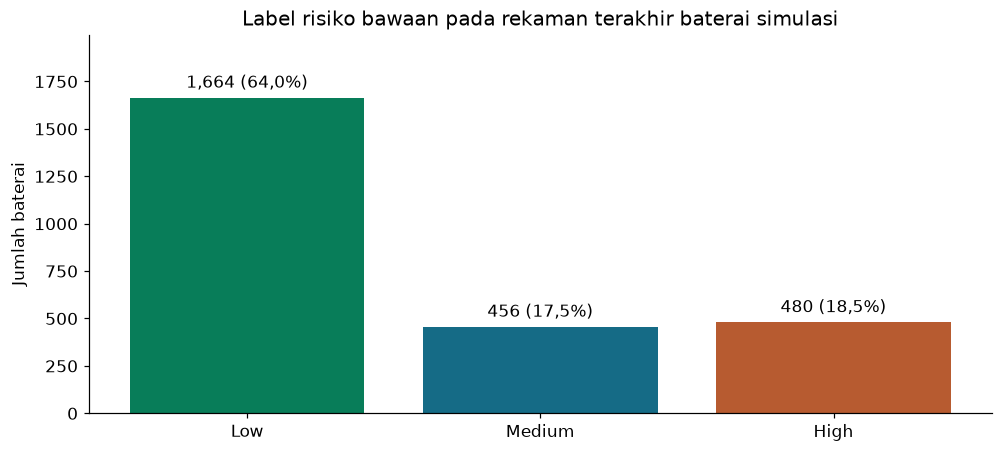

,n,pct
label,,
Low,1664,64.00
Medium,456,17.54
High,480,18.46


failure_risk_label,High,Low,Medium
SOH < 80%,,,
False,29,1663,358
True,451,1,98


**Informasi:** label High terdapat pada **480 baterai**. Aturan SOH < 80% **atau** label High menghasilkan **579 kandidat (22,27%)**. Irisan kedua kondisi berjumlah **451**, sehingga kedua jumlah tidak boleh langsung dijumlahkan.

In [9]:
risiko = snapshot['failure_risk_label'].value_counts().reindex(['Low','Medium','High'], fill_value=0).rename_axis('label').to_frame('n')
risiko['pct'] = risiko['n'] / len(snapshot) * 100
fig, ax = plt.subplots(figsize=(9,4), layout='constrained')
bars = ax.bar(risiko.index, risiko['n'], color=[WARNA['hijau'],WARNA['utama'],WARNA['jingga']])
ax.bar_label(bars, labels=[f'{n:,} ({angka(p,1)}%)' for n,p in zip(risiko['n'],risiko['pct'])], padding=4)
ax.set(ylim=(0,risiko['n'].max()*1.2), ylabel='Jumlah baterai', title='Label risiko bawaan pada rekaman terakhir baterai simulasi')
simpan_grafik(fig, '05_label_risiko.png')
display(risiko)
display(pd.crosstab(snapshot['state_of_health_pct'].lt(80).rename('SOH < 80%'), snapshot['failure_risk_label']))

# Aturan skrining ilustratif: dua kondisi berbeda, digabung OR tanpa menghitung dua kali.
snapshot['kandidat_inspeksi'] = snapshot['state_of_health_pct'].lt(80) | snapshot['failure_risk_label'].eq('High')
n_kandidat = int(snapshot['kandidat_inspeksi'].sum())
irisan = int((snapshot['state_of_health_pct'].lt(80) & snapshot['failure_risk_label'].eq('High')).sum())
assert n_kandidat == n_rendah + int(risiko.loc['High','n']) - irisan
display(Markdown(f'**Informasi:** label High terdapat pada **{int(risiko.loc["High","n"]):,} baterai**. '
                 f'Aturan SOH < 80% **atau** label High menghasilkan **{n_kandidat:,} kandidat '
                 f'({angka(n_kandidat/len(snapshot)*100)}%)**. Irisan kedua kondisi berjumlah **{irisan:,}**, '
                 'sehingga kedua jumlah tidak boleh langsung dijumlahkan.'))

**Informasi strategis:** beban pemeriksaan pada skenario ini lebih besar daripada kelompok High saja,
karena kapasitas rendah dan label risiko adalah indikator berbeda. **Usulan:** uji pemeringkatan
inspeksi berdasarkan kebutuhan kapasitas, data sensor, biaya, dan kapasitas petugas.
Kandidat bukan jumlah baterai yang terbukti gagal atau wajib diganti.

## 9. Visual 6 Sensitivitas ambang skrining

Bandingkan SOH < 75, 80, atau 85%, selalu digabung dengan label High.
Bar chart menunjukkan bahwa ukuran antrean mengikuti kebijakan, bukan hanya karakter data.

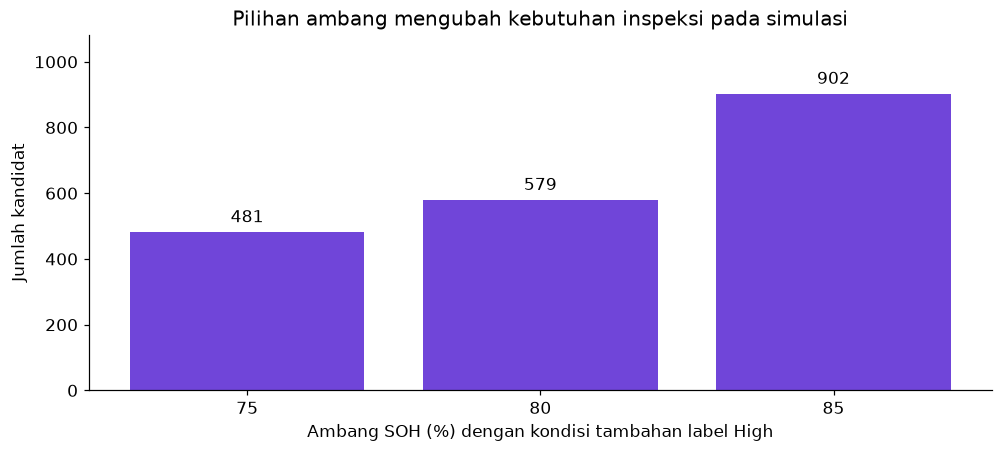

,ambang_soh_pct,kandidat,pct_baterai
0,75,481,18.50
1,80,579,22.27
2,85,902,34.69


In [10]:
sensitivitas = pd.DataFrame([
    {'ambang_soh_pct':ambang, 'kandidat':int((soh.lt(ambang) | snapshot['failure_risk_label'].eq('High')).sum())}
    for ambang in [75,80,85]
])
sensitivitas['pct_baterai'] = sensitivitas['kandidat']/len(snapshot)*100
fig, ax = plt.subplots(figsize=(9,4), layout='constrained')
bars = ax.bar(sensitivitas['ambang_soh_pct'].astype(str), sensitivitas['kandidat'], color=WARNA['ungu'])
ax.bar_label(bars, padding=4)
ax.set(ylim=(0,sensitivitas['kandidat'].max()*1.2), xlabel='Ambang SOH (%) dengan kondisi tambahan label High',
       ylabel='Jumlah kandidat', title='Pilihan ambang mengubah kebutuhan inspeksi pada simulasi')
simpan_grafik(fig, '06_sensitivitas_ambang.png')
display(sensitivitas)

## 10. Kejujuran analisis dan prinsip visualisasi

- Semua judul, satuan, ukuran kelompok, dan penyebut ditampilkan. Batang dimulai dari nol.
- Warna menyatakan kategori atau kepadatan tertentu, bukan penilaian keamanan. Satu grafik menjawab satu pertanyaan.
- Statistik snapshot memberi bobot yang sama ke setiap baterai. Tanggal terakhir berbeda antar-ID.
- Nilai sensor yang hilang tidak diisi nol. Jumlah pasangan lengkap dicantumkan untuk korelasi.
- Dataset sintetis membatasi penerapan ke armada nyata. Korelasi tidak membuktikan sebab-akibat.
- `capacity_fade_pct` didefinisikan sebagai 100 − SOH. Korelasinya dengan SOH bersifat matematis,
  bukan penemuan faktor penyebab. RUL dan label risiko adalah target generator, bukan hasil diagnosis notebook.
- Jika suatu saat membuat model, pisahkan data berdasarkan `battery_id`, bukan acak per baris,
  agar pengukuran baterai yang sama tidak bocor ke data uji. Tidak ada klaim akurasi model pada tugas ini.

## 11. Penjelasan singkat saat responsi

“Aku memeriksa kualitas dan memilih satu pengamatan terakhir per baterai supaya baterai yang
sering diukur tidak mendominasi hasil. Histogram menunjukkan sebaran SOH, hexbin menunjukkan
hubungan dengan siklus, dan boxplot serta heatmap membandingkan kelompok. Hasil tentang kondisi
itu merupakan informasi. Ketika dikaitkan dengan tujuan merencanakan inspeksi, hasilnya menjadi
informasi strategis. Karena datanya sintetis, aturan inspeksi ini sebatas latihan yang perlu
divalidasi dengan data nyata.”

In [11]:
kimia.to_csv(HASIL / 'ringkasan_kimia.csv')
cohort.to_csv(HASIL / 'cohort_umur_kimia.csv', index=False)
risiko.to_csv(HASIL / 'label_risiko.csv')
sensitivitas.to_csv(HASIL / 'sensitivitas.csv', index=False)
snapshot.to_csv(HASIL / 'snapshot_baterai.csv', index=False)
snapshot[snapshot['kandidat_inspeksi']].to_csv(HASIL / 'kandidat_inspeksi.csv', index=False)
ringkasan = {'observasi':len(raw),'baterai':len(snapshot), 'missing_tanggal':int(data['observation_date'].isna().sum()),
             'kimia_dipulihkan':kimia_diisi, 'median_soh':median_soh,'soh_di_bawah_80':n_rendah,
             'kandidat':n_kandidat,'kandidat_pct':n_kandidat/len(snapshot)*100,
             'high':int(risiko.loc['High','n']),'korelasi_siklus_soh':r_siklus,'n_pasangan':len(pasangan),
             'snapshot_mulai':str(snapshot['observation_date'].min().date()),
             'snapshot_akhir':str(snapshot['observation_date'].max().date()),
             'sha256':hashlib.sha256((SUMBER/'ev_battery_health.csv').read_bytes()).hexdigest()}
(HASIL/'ringkasan.json').write_text(json.dumps(ringkasan, indent=2), encoding='utf-8')
assert risiko['n'].sum() == len(snapshot)
assert hist_count.sum() == len(snapshot)
assert sensitivitas['kandidat'].is_monotonic_increasing
print('Selesai. Grafik, audit, snapshot, dan tabel tersimpan di', HASIL)

Selesai. Grafik, audit, snapshot, dan tabel tersimpan di /home/luis/Documents/Codelabs/Sub-Riset/RISET30OKTOBER/Analisis/hasil/battery


## Sumber

- [EV Battery Health & Degradation Dataset di Kaggle](https://www.kaggle.com/datasets/vinay24baghira/ev-battery-health-and-degradation-dataset).
- `Battery/Dataset/archive.zip`, anggota `README.md`: asal sintetis, desain pengukuran berulang,
  injeksi data kosong/pencilan, dan definisi target. README serta kamus dibaca sebagai dokumentasi data.
- `Battery/Dataset/data_dictionary .csv`: satuan dan definisi variabel.
- Angka, grafik, dan aturan skrining merupakan pengolahan sendiri pada file lokal yang disediakan pengguna.